# Separate Project.

In [1]:
import pandas as pd 

In [3]:
price_path = "/Users/parvezali/FYP_Shahzad/Dataset/TSLA_synthetic.csv"
news_path = "/Users/parvezali/FYP_Shahzad/Dataset/TSLA_news.csv"
df_price = pd.read_csv(price_path, parse_dates=["datetime"])
df_news = pd.read_csv(news_path, parse_dates=["datetime"])
df_price = df_price.sort_values('datetime')
df_news = df_news.sort_values('datetime')

In [4]:
df_merged = pd.merge_asof(
    df_price,
    df_news[['datetime', 'sentiment', 'title', 'content']],
    on='datetime',
    direction='backward'
)


In [5]:
df_merged['target_close_1m'] = df_merged['close'].shift(-1)

In [1]:
# Part 1: load data, basic features, and sentiment extraction setup

import pandas as pd
import numpy as np
from tqdm import tqdm

# For sentiment (Hugging Face)
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
import torch

# Utilities
from sklearn.preprocessing import StandardScaler
import math

/Users/parvezali/FYP_Shahzad/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:


# --------- 1) Load & basic cleaning ----------
# adjust path as needed
df = df_merged.copy()
df = df.sort_values("datetime").reset_index(drop=True)

# drop exact duplicates by datetime if any
df = df.drop_duplicates(subset=["datetime"])

# ensure numeric columns are correct dtype
for c in ["open","high","low","close","volume","sentiment","target_close_1m"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# --------- 2) Combine title + content ----------
# create a single text field to pass to the sentiment model
df["title"] = df["title"].fillna("")
df["content"] = df["content"].fillna("")
df["text"] = (df["title"].str.strip() + ". " + df["content"].str.strip()).str.strip()

# --------- 3) Time features (including cyclical encodings) ----------
df["hour"] = df["datetime"].dt.hour
df["minute"] = df["datetime"].dt.minute
df["weekday"] = df["datetime"].dt.weekday  # Monday=0

# cyclical transform (keeps continuity 23 -> 0)
def cyclical_encode(values, period):
    radians = 2 * math.pi * values / period
    return np.sin(radians), np.cos(radians)

df["hour_sin"], df["hour_cos"] = cyclical_encode(df["hour"].values, 24)
df["minute_sin"], df["minute_cos"] = cyclical_encode(df["minute"].values, 60)
# weekday as sin/cos optional:
df["weekday_sin"], df["weekday_cos"] = cyclical_encode(df["weekday"].values, 7)

# --------- 4) Set up pretrained sentiment model (FinBERT) ----------
# Model choice: ProsusAI/finbert (finance-specific). You can change this if desired.
MODEL_NAME = "ProsusAI/finbert"  # finance BERT; change if you prefer another model

device = 0 if torch.cuda.is_available() else -1
print("Using device:", "cuda" if device == 0 else "cpu")

# Create pipeline
# Note: The label mapping depends on the model. ProsusAI/finbert produces labels like NEGATIVE/NEUTRAL/POSITIVE.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer, device=device)

# --------- 5) Batch sentiment scoring function ----------
def compute_sentiment_scores(texts, batch_size=16, progress=True):
    """
    texts: iterable of strings
    returns: list of numeric sentiment scores (pos_prob - neg_prob)
    """
    scores = []
    it = range(0, len(texts), batch_size)
    if progress:
        it = tqdm(it, desc="Sentiment batches")
    for i in it:
        batch = list(texts[i : i + batch_size])
        # pipeline returns a list of dicts: [{'label': 'NEGATIVE', 'score': 0.99}, ...]
        results = sentiment_pipe(batch)
        # Convert to numeric score: pos_prob - neg_prob
        for r in results:
            label = r.get("label", "").lower()
            prob = float(r.get("score", 0.0))
            # some models only return label+score where score corresponds to the label's prob.
            # We convert to a signed score:
            if "positive" in label:
                numeric = prob
            elif "negative" in label:
                numeric = -prob
            elif "neutral" in label:
                numeric = 0.0
            else:
                numeric = 0.0
            scores.append(numeric)
    return scores

# --------- 6) (Optional) quick test on a few rows ----------
sample_texts = df["text"].iloc[:8].tolist()
print("Sample texts:", sample_texts[:2])
sample_scores = compute_sentiment_scores(sample_texts, batch_size=4)
print("Sample sentiment scores:", sample_scores)

# --------- 7) Compute sentiment for whole DataFrame (may take time) ----------
# Uncomment to run for entire DF. Save scores back to df["news_sentiment_score"]
df["news_sentiment_score"] = compute_sentiment_scores(df["text"].tolist(), batch_size=16)




/Users/parvezali/FYP_Shahzad/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


Device set to use cpu


Sample texts: ['Tesla experiences slight dip in market session. Market analysts provided mixed opinions on Tesla following recent developments.', 'Tesla experiences slight dip in market session. Market analysts provided mixed opinions on Tesla following recent developments.']


Sentiment batches: 100%|██████████| 2/2 [00:00<00:00,  3.54it/s]

Sample sentiment scores: [-0.9612464308738708, -0.9612464308738708, -0.9612464308738708, -0.9612464308738708, -0.9612464308738708, -0.9612464308738708, -0.9612464308738708, -0.9612464308738708]


In [9]:
df["news_sentiment_score"] = compute_sentiment_scores(df["text"].tolist(), batch_size=16)


Sentiment batches: 100%|██████████| 2500/2500 [31:30<00:00,  1.32it/s]


In [11]:
df.to_csv("sentements_data_processed.csv", index = False)

# Trainign steps 2 

In [1]:
import pandas as pd
df = pd.read_csv("/Users/parvezali/FYP_Shahzad/sentements_data_processed.csv")

In [3]:
df


,datetime,open,high,low,close,volume,sentiment,title,content,target_close_1m,...,hour,minute,weekday,hour_sin,hour_cos,minute_sin,minute_cos,weekday_sin,weekday_cos,news_sentiment_score
0,2020-01-01 00:00:00,217.539074,217.741660,214.486801,216.039313,153900,-0.127863,Tesla experiences slight dip in market session,Market analysts provided mixed opinions on Tes...,218.093894,...,0,0,2,0.0,1.000000e+00,0.000000,1.000000,0.974928,-0.222521,-0.961246
1,2020-01-01 00:01:00,217.164646,218.159434,217.156787,218.093894,171804,-0.127863,Tesla experiences slight dip in market session,Market analysts provided mixed opinions on Tes...,217.645384,...,0,1,2,0.0,1.000000e+00,0.104528,0.994522,0.974928,-0.222521,-0.961246
2,2020-01-01 00:02:00,216.766662,218.132223,217.537151,217.645384,119668,-0.127863,Tesla experiences slight dip in market session,Market analysts provided mixed opinions on Tes...,219.841321,...,0,2,2,0.0,1.000000e+00,0.207912,0.978148,0.974928,-0.222521,-0.961246
3,2020-01-01 00:03:00,217.519226,219.556737,218.800402,219.841321,59292,-0.127863,Tesla experiences slight dip in market session,Market analysts provided mixed opinions on Tes...,217.061848,...,0,3,2,0.0,1.000000e+00,0.309017,0.951057,0.974928,-0.222521,-0.961246
4,2020-01-01 00:04:00,220.290629,220.352043,217.938195,217.061848,111590,-0.127863,Tesla experiences slight dip in market session,Market analysts provided mixed opinions on Tes...,217.766170,...,0,4,2,0.0,1.000000e+00,0.406737,0.913545,0.974928,-0.222521,-0.961246
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,2020-01-28 18:35:00,269.926120,270.704828,269.537050,269.611516,24603,0.350146,Analysts update forecast for Tesla,Market analysts provided mixed opinions on Tes...,268.348805,...,18,35,1,-1.0,-1.836970e-16,-0.500000,-0.866025,0.781831,0.623490,-0.877584
39996,2020-01-28 18:36:00,270.329027,270.586834,269.207369,268.348805,91161,0.350146,Analysts update forecast for Tesla,Market analysts provided mixed opinions on Tes...,269.520803,...,18,36,1,-1.0,-1.836970e-16,-0.587785,-0.809017,0.781831,0.623490,-0.877584
39997,2020-01-28 18:37:00,270.297152,269.801513,268.009134,269.520803,16817,0.350146,Analysts update forecast for Tesla,Market analysts provided mixed opinions on Tes...,267.760015,...,18,37,1,-1.0,-1.836970e-16,-0.669131,-0.743145,0.781831,0.623490,-0.877584
39998,2020-01-28 18:38:00,268.343596,269.405803,268.532574,267.760015,50521,0.350146,Analysts update forecast for Tesla,Market analysts provided mixed opinions on Tes...,268.825886,...,18,38,1,-1.0,-1.836970e-16,-0.743145,-0.669131,0.781831,0.623490,-0.877584


In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Assume df is your DataFrame with 'close' and 'news_sentiment_score'
# features = df[['open','high','low','close','volume','news_sentiment_score']].values

features = df[['close', 'news_sentiment_score']].values # This one

# Scale features between 0 and 1
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(features)

# Window size
window_size = 10 # This one

# Create sequences
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size, 0])  # predicting close price
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_features, window_size)
print(X.shape, y.shape)  # (num_samples, 10, 2), (num_samples,)


(39990, 10, 2) (39990,)


In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
# This one, LSTM RNN model 
model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(window_size, 2)))
model.add(Dense(1))  # predicting close price
model.compile(optimizer='adam', loss='mse') # This one

model.summary()


/Users/parvezali/FYP_Shahzad/venv/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,651 (41.61 KB)

 Trainable params: 10,651 (41.61 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
import pickle
from sklearn.preprocessing import MinMaxScaler
import numpy as np


pickle.dump(scaler, open("scaler_close_sentiment_2f.pkl", "wb"))


In [4]:
split = int(len(X)*0.8) # This one
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]



In [1]:
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test))    # This one

NameError: name 'model' is not defined

250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


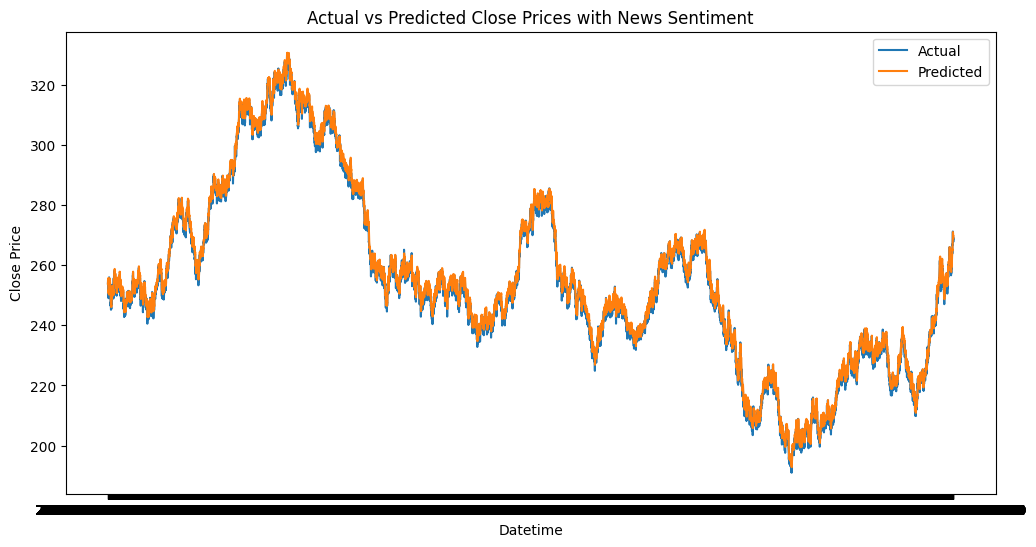

In [43]:
import matplotlib.pyplot as plt

predicted = model.predict(X_test)

# Inverse transform close price only
predicted_prices = scaler.inverse_transform(np.concatenate([predicted, np.zeros((predicted.shape[0],1))], axis=1))[:,0]
actual_prices = scaler.inverse_transform(np.concatenate([y_test.reshape(-1,1), np.zeros((y_test.shape[0],1))], axis=1))[:,0]

plt.figure(figsize=(12,6))
plt.plot(df['datetime'][window_size+split:], actual_prices, label='Actual')
plt.plot(df['datetime'][window_size+split:], predicted_prices, label='Predicted')
plt.xlabel('Datetime')
plt.ylabel('Close Price')
plt.title('Actual vs Predicted Close Prices with News Sentiment')
plt.legend()
plt.show()


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# RMSE
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))

# MAE
mae = mean_absolute_error(actual_prices, predicted_prices)

# R2 Score
r2 = r2_score(actual_prices, predicted_prices)

# MAPE (percentage error)
mape = np.mean(np.abs((actual_prices - predicted_prices) / actual_prices)) * 100

print(f"RMSE: {rmse}")
print(f"MAE: {mae}")
print(f"R2 Score: {r2}")
print(f"MAPE: {mape:.2f}%")


In [49]:
# After training

model.save("lstm_close_sentiment.h5")


In [50]:
import pickle

# Assuming 'scaler' is your fitted MinMaxScaler
with open("scaler_close_sentiment.pkl", "wb") as f:
    pickle.dump(scaler, f)


In [51]:
from tensorflow.keras.models import load_model
import joblib

model = load_model(
    "/Users/parvezali/FYP_Shahzad/lstm_close_sentiment.h5",
    compile=False
)
scaler = joblib.load("/Users/parvezali/FYP_Shahzad/scaler_close_sentiment_2f.pkl")


In [59]:
import streamlit as st
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
import pickle
import pandas as pd
import numpy as np
from tqdm import tqdm

# For sentiment (Hugging Face)
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
import torch

# Utilities
from sklearn.preprocessing import StandardScaler
import math
import streamlit as st
import numpy as np
import pickle
import tensorflow as tf
import torch

from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification

# ====================================
#        1) LOAD LSTM & SCALER
# ====================================

@st.cache_resource
def load_price_model():
    model = tf.keras.models.load_model(
        "/Users/parvezali/FYP_Shahzad/lstm_close_sentiment.h5",
        compile=False
    )
    scaler = pickle.load(open(
        "/Users/parvezali/FYP_Shahzad/scaler_close_sentiment_2f.pkl", "rb"
    ))
    return model, scaler

model, scaler = load_price_model()


# ====================================
#      2) LOAD SENTIMENT MODEL
# ====================================

MODEL_NAME = "ProsusAI/finbert"

@st.cache_resource
def load_sentiment_model():
    device = 0 if torch.cuda.is_available() else -1

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)

    sentiment_pipe = pipeline(
        "sentiment-analysis",
        model=model,
        tokenizer=tokenizer,
        device=device
    )
    return sentiment_pipe

sentiment_pipe = load_sentiment_model()


# ====================================
# 3) SENTIMENT SCORE FUNCTION (FAST)
# ====================================

def compute_sentiment_scores(title, content):
    text = (title.strip() + ". " + content.strip()).strip()

    result = sentiment_pipe(text)[0]  # {'label': 'POSITIVE', 'score': 0.98}

    label = result["label"].lower()
    prob = float(result["score"])

    if "positive" in label:
        return prob
    elif "negative" in label:
        return -prob
    return 0.0


In [60]:
def compute_10_step_sentiments(titles, contents):
    """
    titles: list of 10 titles
    contents: list of 10 contents
    returns: numpy array of 10 sentiment scores
    """

    if len(titles) != 10 or len(contents) != 10:
        raise ValueError("You must provide exactly 10 titles and 10 contents")

    sentiments = []

    for t, c in zip(titles, contents):
        s = compute_sentiment_scores(t, c)
        sentiments.append(s)

    return np.array(sentiments)


In [81]:
def predict_next_close(last_10_closes, last_10_titles, last_10_contents):
    """
    Predict the next close price using LSTM + news sentiment.

    Parameters:
        last_10_closes: list or np.array of last 10 close prices
        last_10_titles: list of last 10 news titles
        last_10_contents: list of last 10 news contents

    Returns:
        predicted_price: float, next close price (real scale)
    """

    if len(last_10_closes) != 10:
        raise ValueError("You must provide exactly 10 close prices")
    if len(last_10_titles) != 10 or len(last_10_contents) != 10:
        raise ValueError("You must provide exactly 10 titles and 10 contents")

    # --- 1) Compute 10-step sentiment window ---
    sentiment_scores = compute_10_step_sentiments(last_10_titles, last_10_contents)
    print(sentiment_scores)

    # --- 2) Normalize/clip sentiment to match training distribution ---
    # Adjust min_val/max_val to match the sentiment range your scaler saw during training
    min_val, max_val = 0.0, 0.1
    sentiment_scores = np.clip(sentiment_scores, min_val, max_val)
    

    # --- 3) Create features: [close, sentiment] ---
    features = np.column_stack([last_10_closes, sentiment_scores])

    # --- 4) Scale features using the training scaler ---
    scaled_features = scaler.transform(features)
    print(scaled_features)
    # --- 5) Reshape for LSTM: (1, 10, 2) ---
    X_input = scaled_features.reshape(1, 10, 2)
    print(X_input)
    # --- 6) Predict scaled close ---
    pred_scaled = model.predict(X_input, verbose=0)[0][0]
    print(pred_scaled)
    # --- 7) Inverse scale close only using last row as template ---
    template = scaled_features[-1].copy()
    template[0] = pred_scaled
    predicted_price = scaler.inverse_transform(template.reshape(1,2))[0,0]

    return predicted_price


In [82]:
last_10_closes = df["close"].iloc[-10:].values
last_10_contents = df["content"].iloc[-10:].tolist()
last_10_titles = df['title'].iloc[-10:].tolist()

next_close = predict_next_close(
    last_10_closes,
    last_10_titles,
    last_10_contents
)

print("Predicted Next Close Price:", next_close)



[-0.87758422 -0.87758422 -0.87758422 -0.87758422 -0.87758422 -0.87758422
 -0.87758422 -0.87758422 -0.87758422 -0.87758422]
[[0.07306595 0.        ]
 [0.         0.        ]
 [0.3232699  0.        ]
 [0.47278178 0.        ]
 [1.         0.        ]
 [0.64171377 0.        ]
 [0.36352281 0.        ]
 [0.62172858 0.        ]
 [0.23380503 0.        ]
 [0.46862969 0.        ]]
[[[0.07306595 0.        ]
  [0.         0.        ]
  [0.3232699  0.        ]
  [0.47278178 0.        ]
  [1.         0.        ]
  [0.64171377 0.        ]
  [0.36352281 0.        ]
  [0.62172858 0.        ]
  [0.23380503 0.        ]
  [0.46862969 0.        ]]]
0.026663523
Predicted Next Close Price: 266.81979812419195


In [90]:
last_10_titles

['Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla',
 'Analysts update forecast for Tesla']

In [69]:
X_test

array([[[0.75906275, 0.0913173 ],
        [0.75141407, 0.0913173 ],
        [0.76106662, 0.0913173 ],
        ...,
        [0.75323404, 0.0913173 ],
        [0.75210338, 0.0913173 ],
        [0.75230219, 0.0913173 ]],

       [[0.75141407, 0.0913173 ],
        [0.76106662, 0.0913173 ],
        [0.7594043 , 0.0913173 ],
        ...,
        [0.75210338, 0.0913173 ],
        [0.75230219, 0.0913173 ],
        [0.75475143, 0.0913173 ]],

       [[0.76106662, 0.0913173 ],
        [0.7594043 , 0.0913173 ],
        [0.760876  , 0.0913173 ],
        ...,
        [0.75230219, 0.0913173 ],
        [0.75475143, 0.0913173 ],
        [0.75830086, 0.0913173 ]],

       ...,

       [[0.79099295, 0.04372989],
        [0.78888385, 0.04372989],
        [0.78675717, 0.04372989],
        ...,
        [0.81049638, 0.04372989],
        [0.80525327, 0.04372989],
        [0.80118226, 0.04372989]],

       [[0.78888385, 0.04372989],
        [0.78675717, 0.04372989],
        [0.79693176, 0.04372989],
        .